# GRU generation huis




In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from pathlib import Path
import sys
import time

# GPU gebruiken als deze beschikbaar is
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


# Data inladen

In [23]:
# Projectmap zoeken
ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "prepared_data").exists()
)

split = pd.read_parquet(
    ROOT / "prepared_data" / "model_split.parquet"
).iloc[0]

sys.path.insert(0, str(ROOT))

from exploration.open_meteo_weer_merge import (
    haal_modeldata_op,
    haal_modeldata_voorspelling_op
)

# Data ophalen
df_train = haal_modeldata_op()
df_voorspelling = haal_modeldata_voorspelling_op()

# Alleen huis generation selecteren
train_df = df_train[
    (df_train["location"] == "huis") &
    (df_train["target_type"] == "generation")
].copy()

val_test_df = df_voorspelling[
    (df_voorspelling["location"] == "huis") &
    (df_voorspelling["target_type"] == "generation")
].copy()

# Ontbrekende waarden verwijderen
train_df = train_df.dropna(subset=["pow_imputed"])
val_test_df = val_test_df.dropna(subset=["pow_imputed"])

# Trainingsperiode selecteren
train_df = train_df[
    (train_df["timestamp_nl"] >= split["train_start"]) &
    (train_df["timestamp_nl"] < split["val_start"])
].copy()

# Validatie- en testperiode selecteren
val_test_df = val_test_df[
    (val_test_df["timestamp_nl"] >= split["val_start"]) &
    (val_test_df["timestamp_nl"] < split["test_end"])
].copy()

# Validatie en test afzonderlijk maken
val_df = val_test_df[
    val_test_df["timestamp_nl"] < split["test_start"]
].copy()

test_df = val_test_df[
    val_test_df["timestamp_nl"] >= split["test_start"]
].copy()

# Chronologisch sorteren
train_df = train_df.sort_values("timestamp_nl").reset_index(drop=True)
val_df = val_df.sort_values("timestamp_nl").reset_index(drop=True)
test_df = test_df.sort_values("timestamp_nl").reset_index(drop=True)

print("Aantal rijen:")
print("Train:", len(train_df))
print("Validatie:", len(val_df))
print("Test:", len(test_df))

Aantal rijen:
Train: 35004
Validatie: 7500
Test: 7488


In [24]:
# df.dtypes

## voorspel instellingen

In [25]:
FEATURE_COLS = [
    "pow_imputed",
    "uur_sin",
    "uur_cos",
    "week_sin",
    "week_cos",
    "temperature_2m",
    "shortwave_radiation",
    "relative_humidity_2m"
]

TARGET_COL = "pow_imputed"
target_idx = FEATURE_COLS.index(TARGET_COL)

# Controleren of alle kolommen bestaan
for naam, df in [
    ("train", train_df),
    ("validatie", val_df),
    ("test", test_df)
]:
    ontbrekend = set(FEATURE_COLS) - set(df.columns)

    if ontbrekend:
        raise ValueError(f"Kolommen ontbreken in {naam}: {ontbrekend}")

# Correlatie bekijken op de trainingsdata
corr = train_df[FEATURE_COLS].corr()

print(corr[TARGET_COL].sort_values(ascending=False))

# Data omzetten naar NumPy-arrays
train_raw = train_df[FEATURE_COLS].to_numpy(dtype=np.float32)
val_raw = val_df[FEATURE_COLS].to_numpy(dtype=np.float32)
test_raw = test_df[FEATURE_COLS].to_numpy(dtype=np.float32)

# Gemiddelde en standaarddeviatie alleen op train berekenen
train_mean = train_raw.mean(axis=0)
train_std = train_raw.std(axis=0)

# Delen door nul voorkomen
train_std[train_std == 0] = 1

# Normaliseren
train_data = (train_raw - train_mean) / train_std
val_data = (val_raw - train_mean) / train_std
test_data = (test_raw - train_mean) / train_std

n_features = len(FEATURE_COLS)

print("Aantal features:", n_features)

pow_imputed             1.000000
uur_cos                 0.567516
relative_humidity_2m    0.310666
uur_sin                 0.036272
week_sin               -0.008018
week_cos               -0.015686
temperature_2m         -0.183190
shortwave_radiation    -0.854068
Name: pow_imputed, dtype: float64
Aantal features: 8


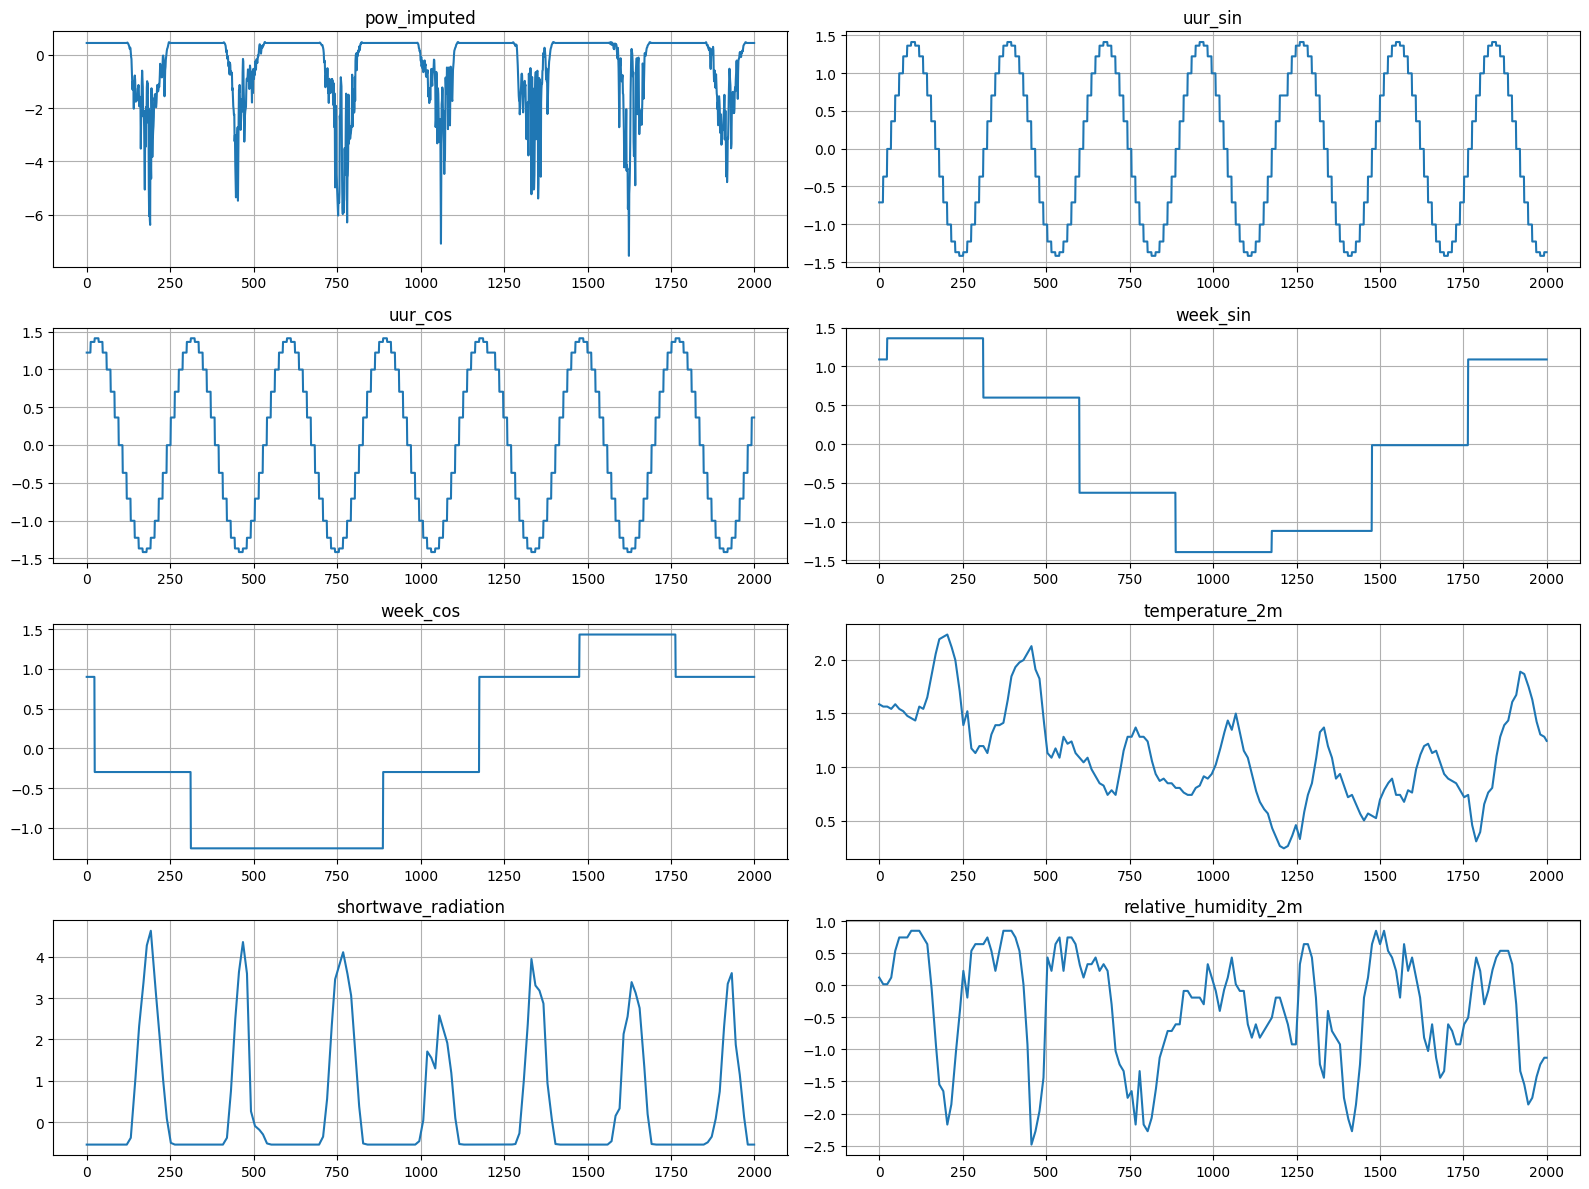

In [26]:
fig, ax = plt.subplots(4, 2, figsize=(16, 12))
ax = ax.flatten()

for i, feature in enumerate(FEATURE_COLS):
    ax[i].plot(train_data[:2000, i])
    ax[i].set_title(feature)
    ax[i].grid(True)

plt.tight_layout()
plt.show()

## chronologisch splisen

In [27]:
stap_per_dag = 24 * 12

aantal_dagen_input = 7
input_len = aantal_dagen_input * stap_per_dag

aantal_dagen_forecast = 3
horizon = aantal_dagen_forecast * stap_per_dag

stride = 12


class WindowDataset(Dataset):

    def __init__(self, data, input_len, horizon, target_idx, stride):

        self.data = torch.tensor(data, dtype=torch.float32)
        self.input_len = input_len
        self.horizon = horizon
        self.target_idx = target_idx

        n_vensters = len(data) - input_len - horizon + 1
        self.starts = range(0, max(n_vensters, 0), stride)

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, idx):

        s = self.starts[idx]

        x = self.data[s:s + self.input_len]

        y = self.data[
            s + self.input_len:s + self.input_len + self.horizon,
            self.target_idx
        ]

        return x, y


# Datasets maken
train_dataset = WindowDataset(
    train_data, input_len, horizon, target_idx, stride
)

val_dataset = WindowDataset(
    val_data, input_len, horizon, target_idx, stride
)

test_dataset = WindowDataset(
    test_data, input_len, horizon, target_idx, stride
)

print(
    "Aantal voorbeelden |",
    "train:", len(train_dataset),
    "| val:", len(val_dataset),
    "| test:", len(test_dataset)
)

if not len(train_dataset) or not len(val_dataset) or not len(test_dataset):
    raise ValueError("Een dataset bevat geen volledige input- en forecastvensters.")

Aantal voorbeelden | train: 2678 | val: 386 | test: 385


Creeer dataset voor de training, validatie en test data.

Creeer DataLoader 

In [28]:
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size
)

## model

## training loop


In [29]:
hidden_sizes = [64, 64]
dropout = 0.2
learning_rate = 1e-3

output_size = horizon


class CustomGRU(nn.Module):

    def __init__(self, input_size, hidden_sizes, output_size, dropout=0.0):
        super().__init__()

        self.layers = nn.ModuleList()
        self.dropout = nn.Dropout(dropout)

        prev_size = input_size

        for h in hidden_sizes:

            self.layers.append(
                nn.GRU(
                    input_size=prev_size,
                    hidden_size=h,
                    num_layers=1,
                    batch_first=True
                )
            )

            prev_size = h

        self.fc = nn.Sequential(
            nn.Linear(hidden_sizes[-1], 128),
            nn.ReLU(),

            nn.Linear(128, 128),
            nn.ReLU(),

            nn.Linear(128, output_size)
        )

    def forward(self, x):

        out = x

        for gru in self.layers:
            out, _ = gru(out)
            out = self.dropout(out)

        out = out[:, -1, :]

        return self.fc(out)


model = CustomGRU(
    input_size=n_features,
    hidden_sizes=hidden_sizes,
    output_size=output_size,
    dropout=dropout
).to(DEVICE)

criterion = nn.L1Loss()

optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate
)

print(
    "CUSTOM GRU |",
    sum(p.numel() for p in model.parameters()),
    "parameters"
)

CUSTOM GRU | 175456 parameters


In [30]:
n_epochs = 30

train_loss_list = []
val_loss_list = []
epoch_time_list = []

std_target = train_std[target_idx]

if DEVICE == "cuda":
    torch.cuda.synchronize()

start_totaal = time.perf_counter()

for epoch in range(n_epochs):

    start_epoch = time.perf_counter()

    # Training
    model.train()
    running_loss = 0.0

    for inputs, targets in train_loader:

        inputs = inputs.to(DEVICE)
        targets = targets.to(DEVICE)

        optimizer.zero_grad()

        output = model(inputs)

        loss = criterion(output, targets)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * targets.shape[0]

    train_loss = running_loss / len(train_dataset)
    train_loss_list.append(train_loss)

    # Validatie
    model.eval()
    val_loss = 0.0

    with torch.no_grad():

        for inputs, targets in val_loader:

            inputs = inputs.to(DEVICE)
            targets = targets.to(DEVICE)

            output = model(inputs)

            loss = criterion(output, targets)

            val_loss += loss.item() * targets.shape[0]

    val_loss = val_loss / len(val_dataset)
    val_loss_list.append(val_loss)

    # Tijd berekenen
    if DEVICE == "cuda":
        torch.cuda.synchronize()

    epoch_tijd = time.perf_counter() - start_epoch
    epoch_time_list.append(epoch_tijd)

    print(
        f"Epoch {epoch+1}/{n_epochs} | "
        f"Train loss: {train_loss:.4f} "
        f"(MAE: {train_loss * std_target:.1f} W) | "
        f"Validatie loss: {val_loss:.4f} "
        f"(MAE: {val_loss * std_target:.1f} W)"
    )

totale_tijd = time.perf_counter() - start_totaal

print(f"\nTotale trainingstijd: {totale_tijd:.1f}s")
print(f"Gemiddeld per epoch: {np.mean(epoch_time_list):.1f}s")

Epoch 1/30 | Train loss: 0.4921 (MAE: 96.4 W) | Validatie loss: 1.9417 (MAE: 380.6 W)
Epoch 2/30 | Train loss: 0.3842 (MAE: 75.3 W) | Validatie loss: 1.7749 (MAE: 347.9 W)
Epoch 3/30 | Train loss: 0.3218 (MAE: 63.1 W) | Validatie loss: 1.7092 (MAE: 335.0 W)
Epoch 4/30 | Train loss: 0.2921 (MAE: 57.3 W) | Validatie loss: 1.6589 (MAE: 325.1 W)
Epoch 5/30 | Train loss: 0.2809 (MAE: 55.0 W) | Validatie loss: 1.6387 (MAE: 321.2 W)
Epoch 6/30 | Train loss: 0.2722 (MAE: 53.4 W) | Validatie loss: 1.6058 (MAE: 314.7 W)
Epoch 7/30 | Train loss: 0.2663 (MAE: 52.2 W) | Validatie loss: 1.6101 (MAE: 315.6 W)
Epoch 8/30 | Train loss: 0.2606 (MAE: 51.1 W) | Validatie loss: 1.5973 (MAE: 313.1 W)
Epoch 9/30 | Train loss: 0.2576 (MAE: 50.5 W) | Validatie loss: 1.5665 (MAE: 307.0 W)
Epoch 10/30 | Train loss: 0.2540 (MAE: 49.8 W) | Validatie loss: 1.5555 (MAE: 304.9 W)
Epoch 11/30 | Train loss: 0.2473 (MAE: 48.5 W) | Validatie loss: 1.5395 (MAE: 301.7 W)
Epoch 12/30 | Train loss: 0.2413 (MAE: 47.3 W) | Val

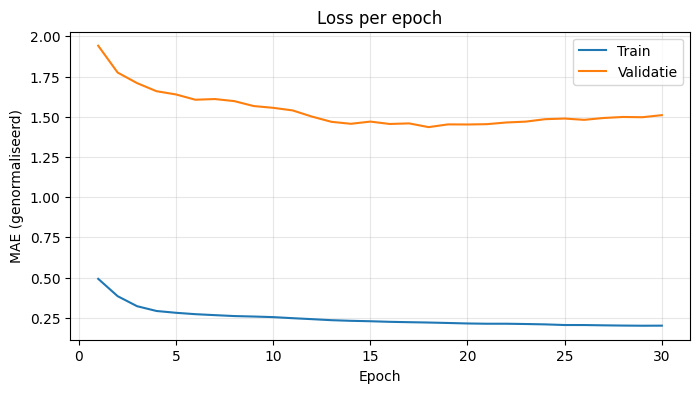

In [31]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, n_epochs + 1), train_loss_list, label='Train')
plt.plot(range(1, n_epochs + 1), val_loss_list, label='Validatie')
plt.xlabel('Epoch')
plt.ylabel('MAE (genormaliseerd)')
plt.title('Loss per epoch')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

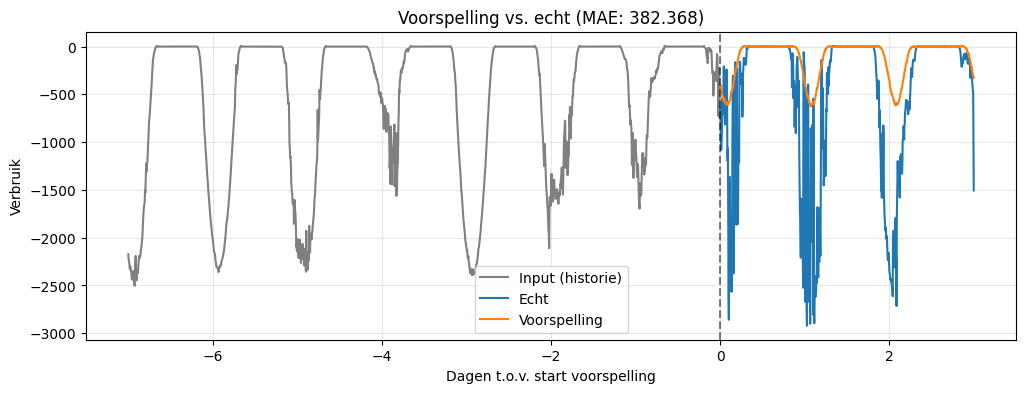

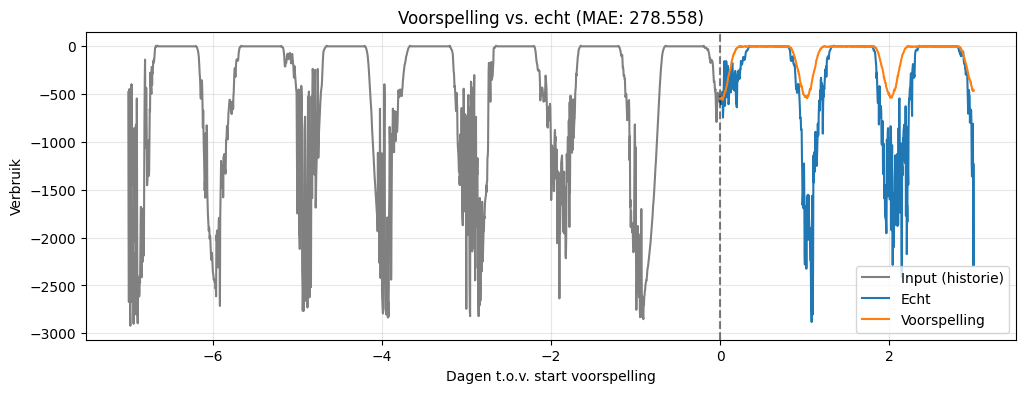

In [32]:
def plot_voorspelling(dataset, idx=0, titel="Voorspelling vs. echt"):

    model.eval()

    x, y = dataset[idx]

    with torch.no_grad():

        pred = model(
            x.unsqueeze(0).to(DEVICE)
        ).cpu().numpy().flatten()

    # Terug naar originele waarden
    m = train_mean[target_idx]
    s = train_std[target_idx]

    hist = x[:, target_idx].numpy() * s + m
    echt = y.numpy() * s + m
    pred = pred * s + m

    mae = np.abs(pred - echt).mean()

    t_hist = np.arange(-input_len, 0) / stap_per_dag
    t_fc = np.arange(horizon) / stap_per_dag

    plt.figure(figsize=(12, 4))

    plt.plot(t_hist, hist, color="grey", label="Input (historie)")
    plt.plot(t_fc, echt, label="Echt")
    plt.plot(t_fc, pred, label="Voorspelling")

    plt.axvline(0, color="black", linestyle="--", alpha=0.5)

    plt.xlabel("Dagen t.o.v. start voorspelling")
    plt.ylabel("Verbruik")
    plt.title(f"{titel} (MAE: {mae:.3f})")

    plt.legend()
    plt.grid(alpha=0.3)

    plt.show()


plot_voorspelling(test_dataset, idx=0)

plot_voorspelling(
    test_dataset,
    idx=len(test_dataset) // 2
)

MAE totaal: 432 W
Dag 1: 434 W
Dag 2: 427 W
Dag 3: 435 W


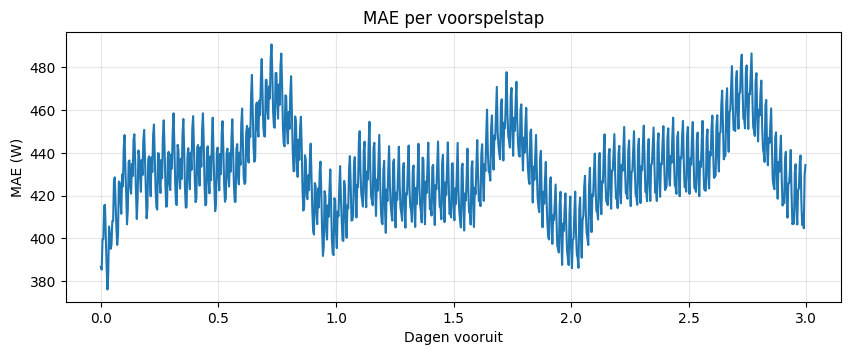

In [33]:
model.eval()

fouten = []

with torch.no_grad():

    for inputs, targets in test_loader:

        inputs = inputs.to(DEVICE)
        targets = targets.to(DEVICE)

        pred = model(inputs)

        fouten.append(
            (pred - targets).abs().cpu()
        )

fouten = torch.cat(fouten).numpy() * std_target

# MAE per voorspelstap
mae_per_stap = fouten.mean(axis=0)

print(f"MAE totaal: {fouten.mean():.0f} W")

for d in range(aantal_dagen_forecast):

    s = slice(
        d * stap_per_dag,
        (d + 1) * stap_per_dag
    )

    print(
        f"Dag {d+1}: {mae_per_stap[s].mean():.0f} W"
    )

# MAE plotten
plt.figure(figsize=(10, 3.5))

plt.plot(
    np.arange(horizon) / stap_per_dag,
    mae_per_stap
)

plt.xlabel("Dagen vooruit")
plt.ylabel("MAE (W)")
plt.title("MAE per voorspelstap")

plt.grid(alpha=0.3)
plt.show()

## Resultaten opslaan
---
- Zelfde format als de andere modellen, opgeslagen in `models/results/`
- MAE in Watt op alle testvensters (elk uur een nieuwe forecast van 3 dagen)
- Persistence dag = zelfde tijdstip van de meest recente bekende dag, persistence week = zelfde tijdstip een week eerder

In [18]:
from pathlib import Path

MODEL_NAAM = "GRU + MLP"
NOTEBOOK = "gru_generation_huis_weer_mlp"
TARGET = "generation"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())
RESULTS_DIR = ROOT / "models" / "results"
MODEL_DIR = ROOT / "models" / "saved_models"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

#Voorspellen op alle testvensters, test_loader schudt niet dus de volgorde klopt
model.eval()
preds, targets_norm = [], []
if DEVICE == "cuda":
    torch.cuda.synchronize()
t0 = time.perf_counter()
with torch.no_grad():
    for inputs, targets in test_loader:
        preds.append(model(inputs.to(DEVICE)).cpu())
        targets_norm.append(targets)
if DEVICE == "cuda":
    torch.cuda.synchronize()
voorspeltijd = time.perf_counter() - t0

m, s = train_mean[target_idx], train_std[target_idx]
pred_test = torch.cat(preds).numpy() * s + m

#Echte waarden en baselines direct uit de reeks in Watt
y_arr = huis_generation[TARGET_COL].to_numpy()
test_origins = i_val + input_len + np.array(test_dataset.starts)
h = np.arange(horizon)
t = test_origins[:, None] + h[None, :]
echt_test = y_arr[t]
base_dag = y_arr[t - stap_per_dag * (h // stap_per_dag + 1)]
base_week = y_arr[t - input_len]
assert np.allclose(torch.cat(targets_norm).numpy() * s + m, echt_test, atol=1.0), "testvensters komen niet overeen"


def scores(pred, echt):
    fout = pred - echt
    res = {"MAE": np.abs(fout).mean(), "RMSE": np.sqrt((fout ** 2).mean())}
    for d in range(aantal_dagen_forecast):
        sl = slice(d * stap_per_dag, (d + 1) * stap_per_dag)
        res[f"MAE dag {d+1}"] = np.abs(fout[:, sl]).mean()
    #Rolling validation: elke dag een nieuwe forecast
    dagelijks = slice(None, None, stap_per_dag // stride)
    res["rolling MAE"] = np.abs(fout[dagelijks]).mean(axis=1).mean()
    res["rolling RMSE"] = np.sqrt((fout[dagelijks] ** 2).mean(axis=1)).mean()
    return res

alle = {MODEL_NAAM: pred_test, "Persistence dag": base_dag, "Persistence week": base_week}
resultaten = pd.DataFrame({naam: scores(pred, echt_test) for naam, pred in alle.items()}).T
resultaten.loc[MODEL_NAAM, "trainingstijd (s)"] = totale_tijd
resultaten.loc[MODEL_NAAM, "voorspeltijd (s)"] = voorspeltijd
resultaten = resultaten.round(1)

#Model opslaan en bestandsgrootte meten
pad = MODEL_DIR / f"{NOTEBOOK}.pt"
torch.save(model.state_dict(), pad)
resultaten.loc[MODEL_NAAM, "modelgrootte (MB)"] = round(pad.stat().st_size / 1e6, 3)

KOLOMMEN = ["notebook", "locatie", "target", "resolutie", "testperiode", "MAE", "RMSE", "MAE dag 1", "MAE dag 2",
            "MAE dag 3", "rolling MAE", "rolling RMSE", "trainingstijd (s)", "voorspeltijd (s)",
            "modelgrootte (MB)"]
tijden = pd.to_datetime(huis_generation["timestamp"])
resultaten["notebook"] = NOTEBOOK
resultaten["locatie"] = "huis"
resultaten["target"] = TARGET
resultaten["resolutie"] = "5 min"
resultaten["testperiode"] = f"{tijden.iloc[i_val]:%Y-%m-%d} t/m {tijden.iloc[-1]:%Y-%m-%d}"
resultaten = resultaten.reindex(columns=KOLOMMEN)
resultaten.to_csv(RESULTS_DIR / f"{NOTEBOOK}.csv")
resultaten

NameError: name 'huis_generation' is not defined